In [2]:
import tensorflow as tf
IMG_HEIGHT=224
IMG_WIDTH=224
IMG_CHANNELS=3
CLASS_NAMES = ["daisy", "dandelion", "roses", "sunflowers", "tulips"]

In [4]:
def read_and_decode(filename, resize_dims):
    # 1. Read the raw file
    img_bytes = tf.io.read_file(filename) #raw content of file ko read karta 
    # 2. Decode image data
    img = tf.image.decode_jpeg(img_bytes, channels=IMG_CHANNELS) #jpeg image compressed and encoded regti to pehle usko decode karte and vo integere me decode hoti
    # 3. Convert pixel values to floats in [0, 1]
    img = tf.image.convert_image_dtype(img, tf.float32) # converting the integere into float in a scale range of 0-1 (normalized values)
    # 4. Resize the image to match desired dimensions
    img = tf.image.resize(img, resize_dims) #resizing to a particular dimesions because all images may be of diff dimensions
    return img

In [5]:
def parse_csvline(csv_line):
    # record_defaults specify the data types for each column
    record_default = ["", ""]
    filename, label_string = tf.io.decode_csv(csv_line, record_default)

    # Load the image
    img = read_and_decode(filename, [IMG_HEIGHT, IMG_WIDTH])

    # Convert label string to integer based on the CLASS_NAMES index
    label = tf.argmax(tf.math.equal(CLASS_NAMES, label_string))
    return img, label

In [12]:
import tensorflow as tf
import pathlib
import tarfile
import urllib.request

data_dir = pathlib.Path("data/flower_photos").resolve()
data_dir.parent.mkdir(parents=True, exist_ok=True)

archive = data_dir.parent / "flower_photos.tgz"
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

if not data_dir.exists():
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, archive)

    print("Extracting dataset...")
    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall(path=data_dir.parent)

print("Dataset exists:", data_dir.exists())
print("Classes:", sorted(p.name for p in data_dir.iterdir() if p.is_dir()))

Extracting dataset...


C:\Users\windows\AppData\Local\Temp\ipykernel_7104\2510414288.py:18: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=data_dir.parent)


Dataset exists: True
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [13]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 16

train_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

eval_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

CLASS_NAMES = train_dataset.class_names

print("Classes:", CLASS_NAMES)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [14]:
for image_batch, label_batch in train_dataset.take(1):
    print("Image batch shape:", image_batch.shape)
    print("Label batch shape:", label_batch.shape)

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)


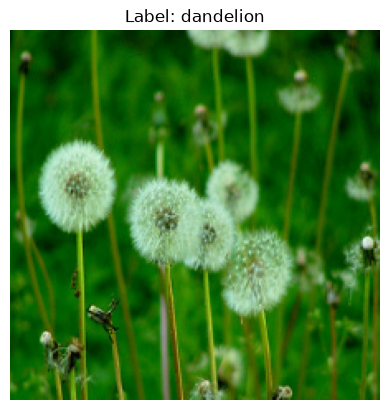

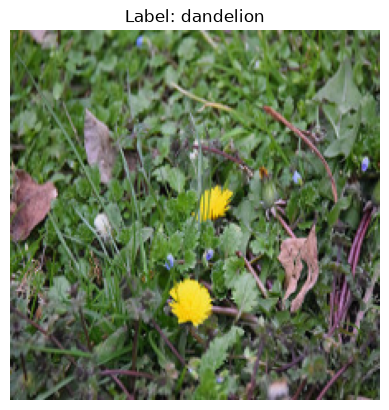

In [17]:

import matplotlib.pyplot as plt

for image_batch, label_batch in train_dataset.take(2):
    first_image = image_batch[0]
    first_label = label_batch[0]

    # Normalize pixel values from [0, 255] to [0, 1]
    first_image = first_image / 255.0

    plt.imshow(first_image.numpy())
    plt.title(f"Label: {CLASS_NAMES[first_label.numpy()]}")
    plt.axis("off")
    plt.show()

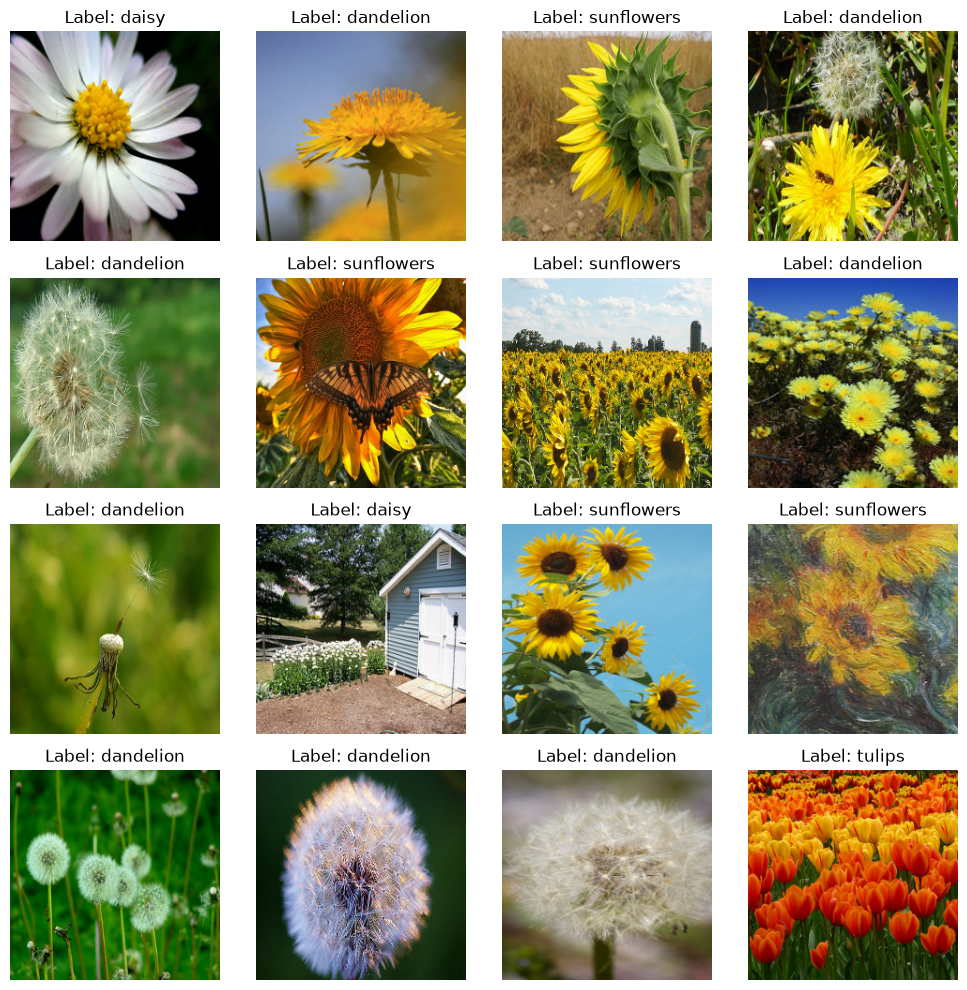

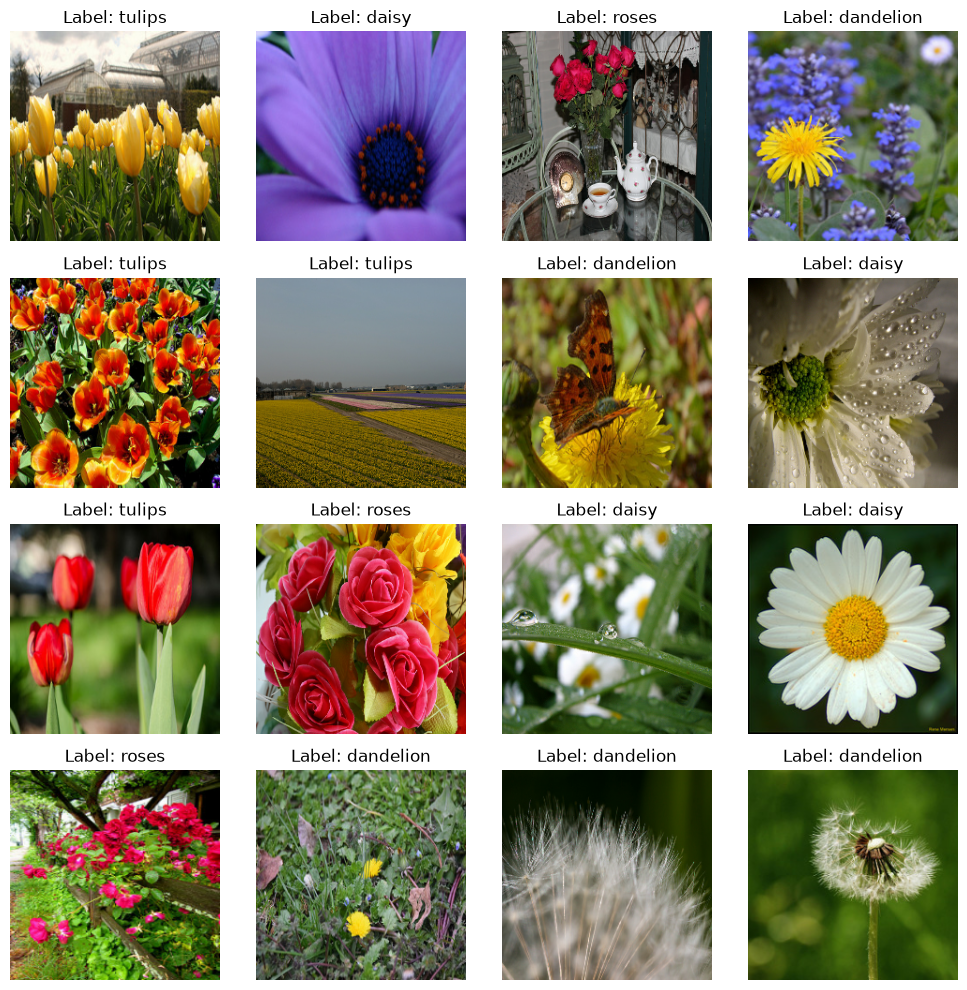

In [18]:

import matplotlib.pyplot as plt

# Take one batch from the dataset
for image_batch, label_batch in train_dataset.take(2):
    fig, axes = plt.subplots(4, 4, figsize=(10, 10))

    for i in range(16):
        ax = axes[i // 4, i % 4]

        # Normalize pixel values to [0, 1]
        image = image_batch[i].numpy() / 255.0

        ax.imshow(image)
        ax.set_title(f"Label: {CLASS_NAMES[label_batch[i].numpy()]}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [19]:
from tensorflow import keras

model = keras.Sequential([
    keras.layers.Flatten(input_shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)),
    keras.layers.Dense(len(CLASS_NAMES), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=["accuracy"]
)

c:\Users\windows\Desktop\projects\computer-vision\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [20]:
EPOCHS = 10

history = model.fit(
    train_dataset,
    validation_data=eval_dataset,
    epochs=EPOCHS
)

Epoch 1/10


c:\Users\windows\Desktop\projects\computer-vision\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


184/184 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.3355 - loss: 4257.1064 - val_accuracy: 0.3447 - val_loss: 5271.1704
Epoch 2/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 8s 42ms/step - accuracy: 0.4155 - loss: 2647.4480 - val_accuracy: 0.3583 - val_loss: 4432.6357
Epoch 3/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.4261 - loss: 3179.7217 - val_accuracy: 0.4237 - val_loss: 2950.6641
Epoch 4/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 8s 43ms/step - accuracy: 0.4860 - loss: 2364.9299 - val_accuracy: 0.4278 - val_loss: 3117.7434
Epoch 5/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 7s 40ms/step - accuracy: 0.5184 - loss: 2077.9023 - val_accuracy: 0.3365 - val_loss: 4074.0466
Epoch 6/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - accuracy: 0.5177 - loss: 2362.9685 - val_accuracy: 0.3420 - val_loss: 4895.0972
Epoch 7/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.5310 - loss: 2353.3601 - val_accuracy: 0.4251 - val_loss: 2599.9800
Epoch 8/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0

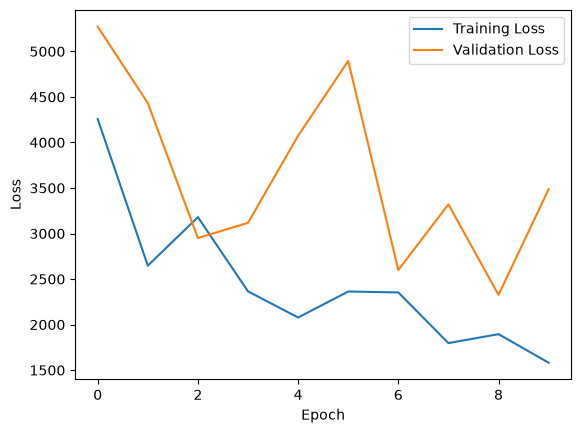

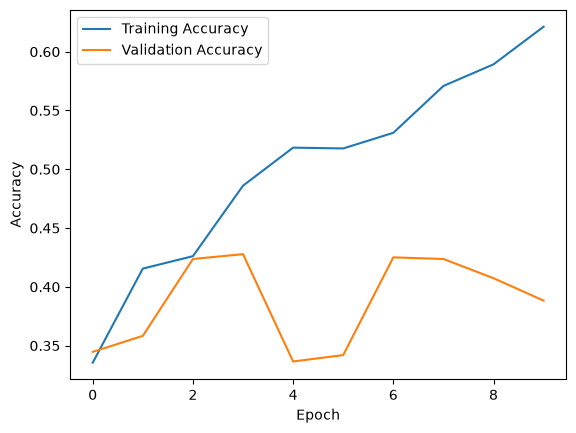

In [21]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

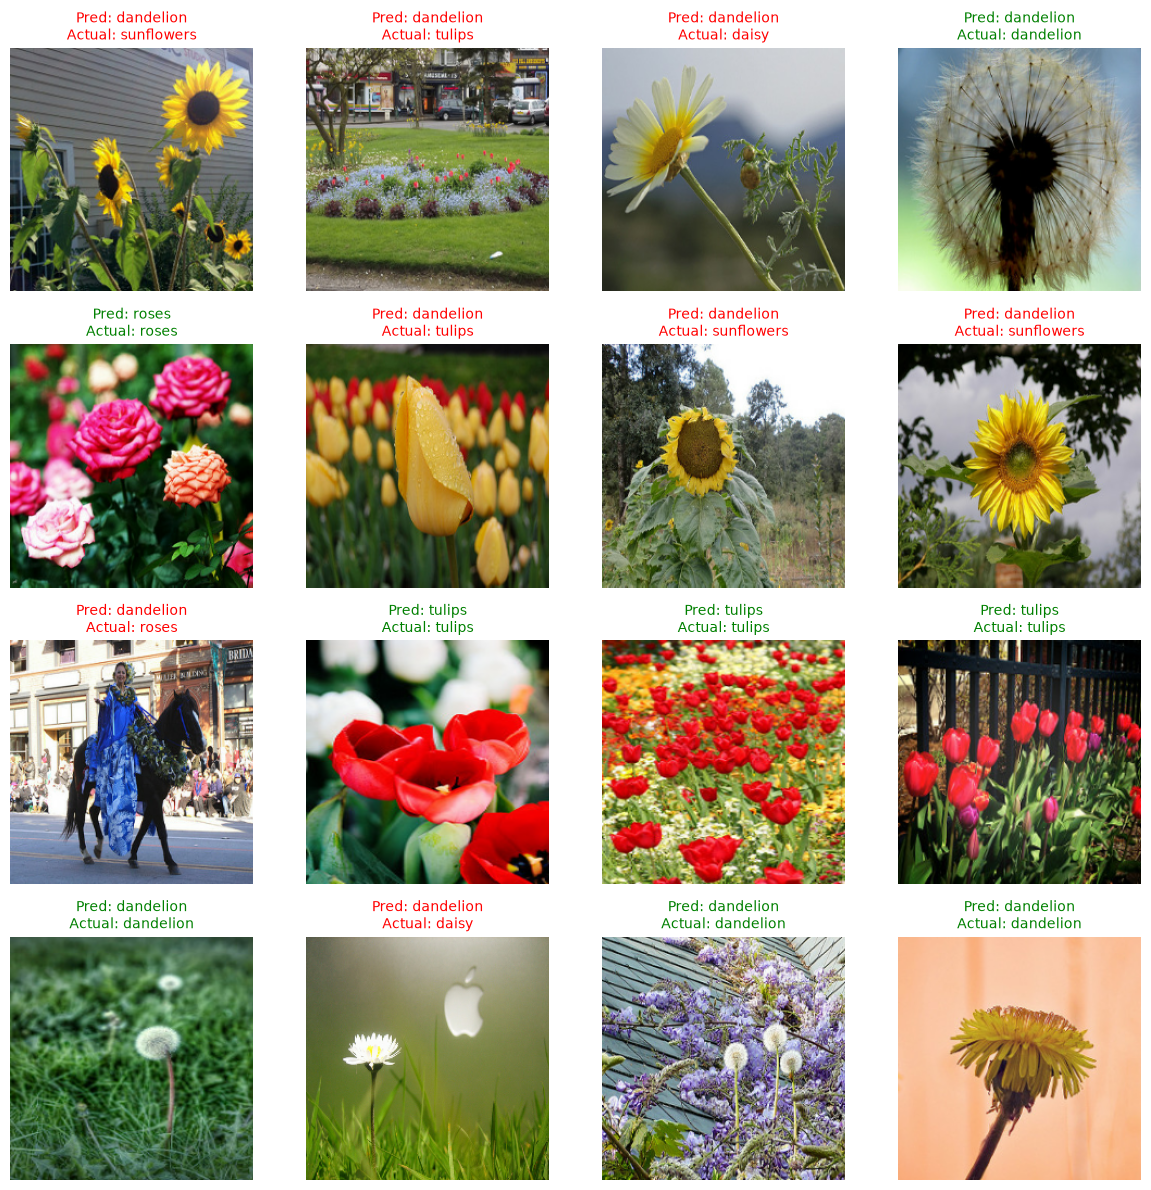

In [23]:

import numpy as np
import matplotlib.pyplot as plt
import math

# Take one batch from the evaluation dataset
for images, labels in eval_dataset.take(1):

    # Get model predictions
    batch_predictions = model.predict(images, verbose=0)

    # Convert prediction probabilities into class indices
    predicted_indices = np.argmax(batch_predictions, axis=1)

    # Calculate grid dimensions
    num_images = images.shape[0]
    num_cols = 4
    num_rows = math.ceil(num_images / num_cols)

    plt.figure(figsize=(12, 3 * num_rows))

    for i in range(num_images):
        plt.subplot(num_rows, num_cols, i + 1)

        # Normalize only for displaying the image
        image = images[i].numpy() / 255.0
        plt.imshow(image)
        plt.axis("off")

        # Get predicted and actual class names
        pred_class = CLASS_NAMES[predicted_indices[i]]
        actual_class = CLASS_NAMES[labels[i].numpy()]

        # Green = correct prediction, red = incorrect prediction
        title_color = "green" if pred_class == actual_class else "red"

        plt.title(
            f"Pred: {pred_class}\nActual: {actual_class}",
            fontsize=10,
            color=title_color
        )

    plt.tight_layout()
    plt.show()